## Table of Contents

- [Packages](#0)
- [Utils](#1)
- [1 - Problem Statement](#2)
- [2 - Transfer Learning](#3)
- [3 - Neural Style Transfer (NST)](#4)
    - [3.1 - Computing the Content Cost](#4-1)
        - [3.1.1 - Make Generated Image G Match the Content of Image C](#4-1-1)
        - [3.1.2 - Content Cost Function  𝐽𝑐𝑜𝑛𝑡𝑒𝑛𝑡(𝐶,𝐺)](#4-1-2)
    - [3.2 - Computing the Style Cost](#4-2)
        - [3.2.1 - Style Matrix](#4-2-1)
            - [Gram Matrix](#ex-2)
        - [3.2.2 - Style Cost](#4-2-2)
            - [Compute Layer Style Cost](#ex-3)
        - [3.2.3 Style Weights](#4-2-3)
            - [Compute Style Cost](#ex-4)
    - [3.3 - Defining the Total Cost to Optimize](#4-3)
        - [Total Cost](#ex-5)
- [4 - Solving the Optimization Problem](#5)
    - [4.1 Load the Content Image](#5-1)
    - [4.2 Load the Style Image](#5-2)
    - [4.3 Randomly Initialize the Image to be Generated](#5-3)
    - [4.4 - Load Pre-trained VGG19 Model](#5-4)
    - [4.5 - Compute Total Cost](#5-5)
        - [4.5.1 - Compute Content Cost](#5-5-1)
        - [4.5.2 - Compute Style Cost](#5-5-2)
            - [Train Step](#ex-6)
    - [4.6 - Train the Model](#5-6)

<a name="0"></a>
## Packages

In [117]:
import pprint

import matplotlib.pyplot as plt
import numpy             as np
import tensorflow        as tf

from matplotlib.pyplot import imshow
from PIL               import Image

<a name="1"></a>
## Utils

In [118]:
%matplotlib inline


def clip_0_1(image):
    """
    Truncate all the pixels in the tensor to be between 0 and 1

    Arguments:
    image -- Tensor
    J_style -- style cost coded above

    Returns:
    Tensor
    """

    return tf.clip_by_value(image, clip_value_min=0.0, clip_value_max=1.0)


def tensor_to_image(tensor):
    """
    Converts the given tensor into a PIL image

    Arguments:
    tensor -- Tensor

    Returns:
    Image: A PIL image
    """

    tensor = tensor * 255
    tensor = np.array(tensor, dtype=np.uint8)

    if np.ndim(tensor) > 3:
        assert tensor.shape[0] == 1
        tensor = tensor[0]

    return Image.fromarray(tensor)

<a name="2"></a>
## 1 - Problem Statement

Neural Style Transfer (NST) is one of the most fun and interesting optimization techniques in deep learning. It merges two images, namely: a <strong>"content" image (C)</strong> and a <strong>"style" image (S)</strong>, to create a <strong>"generated" image (G)</strong>. The generated image G combines the "content" of the image C with the "style" of image S.

<a name="3"></a>
## 2 - Transfer Learning

We will be using the eponymously named VGG network from the [original NST paper](https://arxiv.org/abs/1508.06576) published by the Visual Geometry Group at University of Oxford in 2014. Specifically, you'll use VGG-19, a 19-layer version of the VGG network. This model has already been trained on the very large ImageNet database, and has learned to recognize a variety of low level features (at the shallower layers) and high level features (at the deeper layers).

In [119]:
tf.random.set_seed(999)
pp       = pprint.PrettyPrinter(indent=4)
img_size = 400
vgg      = tf.keras.applications.VGG19(
    include_top = False,
    input_shape = (img_size, img_size, 3),
    weights     = '../models/pretrained/vgg19_weights_tf_dim_ordering_tf_kernels_notop.h5'
)

vgg.trainable = False
pp.pprint(vgg)

<Functional name=vgg19, built=True>


<a name='4'></a>
## 4 - Neural Style Transfer (NST)

- First, We will build the content cost function $J_{content}(C,G)$
- Second, We will build the style cost function $J_{style}(S,G)$
- Finally, We will put it all together to get $J(G) = \alpha J_{content}(C,G) + \beta J_{style}(S,G)$.

<a name='4-1'></a>
### 4.1 - Computing the Content Cost

<a name='4-1-1'></a>
#### 4.1.1 - Make Generated Image G Match the Content of Image C

One goal we should aim for when performing NST is for the content in generated image G to match the content of image C. To do so, we will need an understanding of <b> shallow versus deep layers </b>:

* The shallower layers of a ConvNet tend to detect lower-level features such as <i>edges and simple textures</i>.
* The deeper layers tend to detect higher-level features such as more <i> complex textures and object classes</i>.

#### To choose a "middle" activation layer $a^{[l]}$ :
We need the "generated" image G to have similar content as the input image C. Suppose we have chosen some layer's activations to represent the content of an image.
* In practice, we will usually get the most visually pleasing results if you choose a layer from somewhere in the middle of the network--neither too shallow nor too deep. This ensures that the network detects both higher-level and lower-level features.

#### To forward propagate image "C:"
* Set the image C as the input to the pretrained VGG network, and run forward propagation.
* Let $a^{(C)}$ be the hidden layer activations in the layer you had chosen. This will be an $n_H \times n_W \times n_C$ tensor.

#### To forward propagate image "G":
* Repeat this process with the image G: Set G as the input, and run forward propagation.
* Let $a^{(G)}$ be the corresponding hidden layer activation.

The content image (C) shows the Louvre museum's pyramid surrounded by old Paris buildings, against a sunny sky with a few clouds.


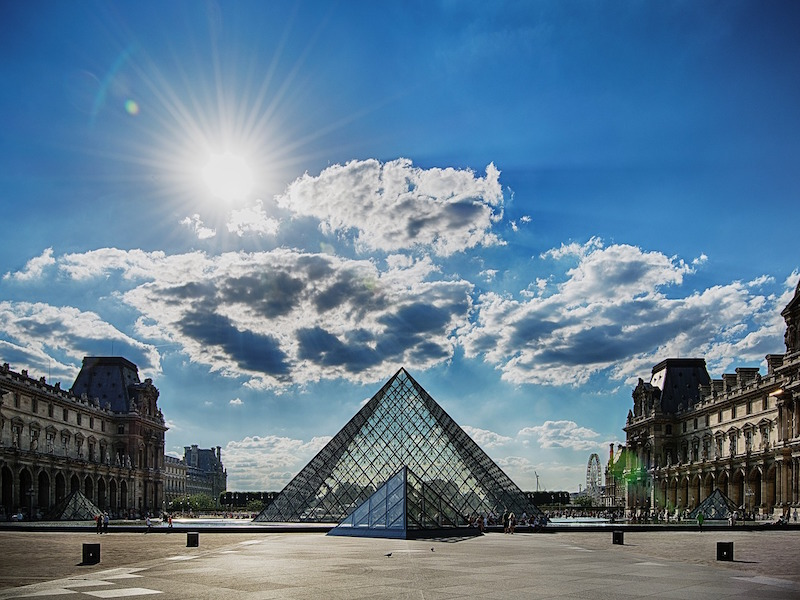

In [120]:
content_image = Image.open("../images/louvre.jpg")
print("The content image (C) shows the Louvre museum's pyramid surrounded by old Paris buildings, against a sunny sky with a few clouds.")
content_image

<a name='4-1-2'></a>
#### 4.1.2 - Content Cost Function $J_{content}(C,G)$
One goal we should aim for when performing NST is for the content in generated image G to match the content of image C. A method to achieve this is to calculate the content cost function, which will be defined as:

$$J_{content}(C,G) =  \frac{1}{4 \times n_H \times n_W \times n_C}\sum _{ \text{all entries}} (a^{(C)} - a^{(G)})^2\tag{1} $$

* Here, $n_H, n_W$ and $n_C$ are the height, width and number of channels of the hidden layer you have chosen, and appear in a normalization term in the cost.
* For clarity, note that $a^{(C)}$ and $a^{(G)}$ are the 3D volumes corresponding to a hidden layer's activations.
* In order to compute the cost $J_{content}(C,G)$, it might also be convenient to unroll these 3D volumes into a 2D matrix, as shown below.
* Technically this unrolling step isn't needed to compute $J_{content}$, but it will be good practice for when you do need to carry out a similar operation later for computing the style cost $J_{style}$.

<img src="../images/NST_LOSS.png" style="width:800px;height:400px;">

In [121]:
def compute_content_cost(content_output, generated_output):
    """
    Computes the content cost

    Arguments:
    a_C -- tensor of dimension (1, n_H, n_W, n_C), hidden layer activations representing content of the image C
    a_G -- tensor of dimension (1, n_H, n_W, n_C), hidden layer activations representing content of the image G

    Returns:
    J_content -- scalar that you compute using equation 1 above.
    """

    a_C = content_output[-1]
    a_G = generated_output[-1]

    # Retrieve dimensions from a_G
    _, n_H, n_W, n_C = a_G.get_shape().as_list()

    # Reshape 'a_C' and 'a_G'
    # DO NOT reshape 'content_output' or 'generated_output'
    a_C_unrolled = tf.transpose(tf.reshape(a_C, shape=[-1, n_H * n_W, n_C]), perm=[0,1,2])
    a_G_unrolled = tf.transpose(tf.reshape(a_G, shape=[-1, n_H * n_W, n_C]), perm=[0,1,2])

    # compute the cost with tensorflow
    J_content = (1 / (4*n_H*n_W*n_C)) * (tf.reduce_sum(tf.square(tf.subtract(a_C_unrolled, a_G_unrolled))))

    return J_content

<a name='4-2'></a>
### 4.2 - Computing the Style Cost

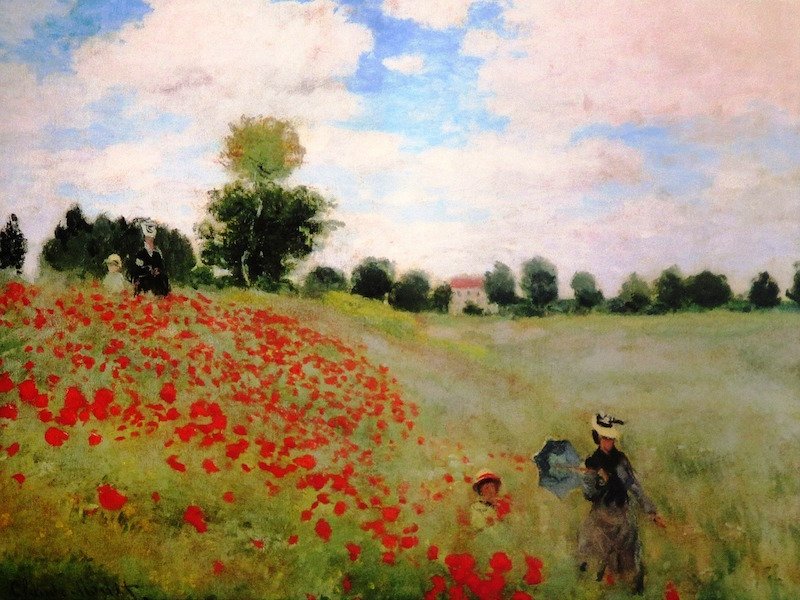

In [122]:
example = Image.open("../images/monet_800600.jpg")
example

<a name='4-2-1'></a>
#### 4.2.1 - Style Matrix

#### Gram matrix
* The style matrix is also called a "Gram matrix."
* In linear algebra, the Gram matrix G of a set of vectors $(v_{1},\dots ,v_{n})$ is the matrix of dot products, whose entries are ${\displaystyle G_{ij} = v_{i}^T v_{j} = np.dot(v_{i}, v_{j})  }$.
* In other words, $G_{ij}$ compares how similar $v_i$ is to $v_j$: If they are highly similar, we would expect them to have a large dot product, and thus for $G_{ij}$ to be large.

#### Two meanings of the variable $G$
* Note that there is an unfortunate collision in the variable names used here. Following the common terminology used in the literature:
    * $G$ is used to denote the Style matrix (or Gram matrix)
    * $G$ also denotes the generated image.
* $G_{gram}$ will be used to refer to the Gram matrix, and $G$ to denote the generated image.


#### Compute Gram matrix $G_{gram}$
We will compute the Style matrix by multiplying the "unrolled" filter matrix with its transpose:

<img src="../images/NST_GM.png" style="width:900px;height:300px;">

$$\mathbf{G}_{gram} = \mathbf{A}_{unrolled} \mathbf{A}_{unrolled}^T$$

#### $G_{(gram)ij}$: correlation
The result is a matrix of dimension $(n_C,n_C)$ where $n_C$ is the number of filters (channels). The value $G_{(gram)i,j}$ measures how similar the activations of filter $i$ are to the activations of filter $j$.

#### $G_{(gram),ii}$: prevalence of patterns or textures
* The diagonal elements $G_{(gram)ii}$ measure how "active" a filter $i$ is.
* For example, suppose filter $i$ is detecting vertical textures in the image. Then $G_{(gram)ii}$ measures how common  vertical textures are in the image as a whole.
* If $G_{(gram)ii}$ is large, this means that the image has a lot of vertical texture.


By capturing the prevalence of different types of features ($G_{(gram)ii}$), as well as how much different features occur together ($G_{(gram)ij}$), the Style matrix $G_{gram}$ measures the style of an image.

<a name='ex-2'></a>
#### Gram Matrix

* The formula is: The gram matrix of A is $G_A = AA^T$.

In [123]:
def gram_matrix(A):
    """
    Argument:
    A -- matrix of shape (n_C, n_H*n_W)

    Returns:
    GA -- Gram matrix of A, of shape (n_C, n_C)
    """

    GA = tf.linalg.matmul(A, tf.transpose(A))

    return GA

<a name='4-2-2'></a>
#### 4.2.2 - Style Cost

We will be to minimize the distance between the Gram matrix of the "style" image S and the Gram matrix of the "generated" image G.
* For now, we will use only a single hidden layer $a^{[l]}$.
* The corresponding style cost for this layer is defined as:

$$J_{style}^{[l]}(S,G) = \frac{1}{4 \times {n_C}^2 \times (n_H \times n_W)^2} \sum _{i=1}^{n_C}\sum_{j=1}^{n_C}(G^{(S)}_{(gram)i,j} - G^{(G)}_{(gram)i,j})^2\tag{2} $$

* $G_{gram}^{(S)}$ Gram matrix of the "style" image.
* $G_{gram}^{(G)}$ Gram matrix of the "generated" image.
* Remember that this cost is computed using the hidden layer activations for a particular hidden layer in the network $a^{[l]}$


<a name='ex-3'></a>
### Compute Layer Style Cost
Compute the style cost for a single layer.

In [124]:
def compute_layer_style_cost(a_S, a_G):
    """
    Arguments:
    a_S -- tensor of dimension (1, n_H, n_W, n_C), hidden layer activations representing style of the image S
    a_G -- tensor of dimension (1, n_H, n_W, n_C), hidden layer activations representing style of the image G

    Returns:
    J_style_layer -- tensor representing a scalar value, style cost defined above by equation (2)
    """

    # Retrieve dimensions from a_G
    _, n_H, n_W, n_C = a_G.get_shape().as_list()

    # Reshape the tensors from (1, n_H, n_W, n_C) to (n_C, n_H * n_W)
    a_S = tf.transpose(tf.reshape(a_S, shape=[n_H * n_W, n_C]), perm=[1, 0])
    a_G = tf.transpose(tf.reshape(a_G, shape=[n_H * n_W, n_C]), perm=[1, 0])

    # Computing gram_matrices for both images S and G
    GS = gram_matrix(a_S)
    GG = gram_matrix(a_G)

    # Computing the loss
    J_style_layer = (1 / (4*(n_C**2)*((n_H*n_W)**2))) * (tf.reduce_sum(tf.square(tf.subtract(GS, GG))))

    return J_style_layer

<a name='4-2-3'></a>
#### 4.2.3 Style Weights

* By default, we will give each layer equal weight, and the weights add up to 1.  ($\sum_{l}^L\lambda^{[l]} = 1$)
* You can combine the style costs for different layers as follows:
$$J_{style}(S,G) = \sum_{l} \lambda^{[l]} J^{[l]}_{style}(S,G)$$
where the values for $\lambda^{[l]}$ are given in `STYLE_LAYERS`.

In [125]:
for layer in vgg.layers:
    print(layer.name)

input_layer_5
block1_conv1
block1_conv2
block1_pool
block2_conv1
block2_conv2
block2_pool
block3_conv1
block3_conv2
block3_conv3
block3_conv4
block3_pool
block4_conv1
block4_conv2
block4_conv3
block4_conv4
block4_pool
block5_conv1
block5_conv2
block5_conv3
block5_conv4
block5_pool


In [126]:
vgg.get_layer('block5_conv4').output

<KerasTensor shape=(None, 25, 25, 512), dtype=float32, sparse=False, ragged=False, name=keras_tensor_130>

In [127]:
STYLE_LAYERS = [
    ('block1_conv1', 0.2),
    ('block2_conv1', 0.2),
    ('block3_conv1', 0.2),
    ('block4_conv1', 0.2),
    ('block5_conv1', 0.2)
]

<a name='ex-4'></a>
#### Compute Style Cost

In [128]:
def compute_style_cost(style_image_output, generated_image_output, STYLE_LAYERS=STYLE_LAYERS):
    """
    Computes the overall style cost from several chosen layers

    Arguments:
    style_image_output -- our tensorflow model
    generated_image_output --
    STYLE_LAYERS -- A python list containing:
                        - the names of the layers we would like to extract style from
                        - a coefficient for each of them

    Returns:
    J_style -- tensor representing a scalar value, style cost defined above by equation (2)
    """

    # initialize the overall style cost
    J_style = 0

    # Set a_S to be the hidden layer activation from the layer we have selected.
    # The last element of the array contains the content layer image, which must not be used.
    a_S = style_image_output[:-1]

    # Set a_G to be the output of the chosen hidden layers.
    # The last element of the list contains the content layer image which must not be used.
    a_G = generated_image_output[:-1]
    for i, weight in zip(range(len(a_S)), STYLE_LAYERS):
        # Compute style_cost for the current layer
        J_style_layer = compute_layer_style_cost(a_S[i], a_G[i])

        # Add weight * J_style_layer of this layer to overall style cost
        J_style += weight[1] * J_style_layer

    return J_style

<a name='4-3'></a>
### 4.3 - Defining the Total Cost to Optimize
Finally, we will create a cost function that minimizes both the style and the content cost. The formula is:
$$J(G) = \alpha J_{content}(C,G) + \beta J_{style}(S,G)$$

<a name='ex-5'></a>
### Total Cost
Implement the total cost function which includes both the content cost and the style cost.

In [129]:
@tf.function()
def total_cost(J_content, J_style, alpha = 10, beta = 40):
    """
    Computes the total cost function

    Arguments:
    J_content -- content cost coded above
    J_style -- style cost coded above
    alpha -- hyperparameter weighting the importance of the content cost
    beta -- hyperparameter weighting the importance of the style cost

    Returns:
    J -- total cost as defined by the formula above.
    """

    J = alpha * J_content + beta * J_style

    return J

<a name='5'></a>
## 5 - Solving the Optimization Problem

<a name='5-1'></a>
### 5.1 Load the Content Image
Run the following code cell to load, reshape, and normalize your "content" image C (the Louvre museum picture):

(1, 400, 400, 3)


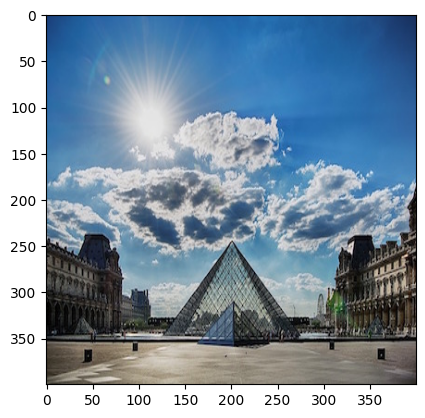

In [130]:
content_image = np.array(Image.open("../images/louvre_small.jpg").resize((img_size, img_size)))
content_image = tf.constant(np.reshape(content_image, ((1,) + content_image.shape)))

print(content_image.shape)
imshow(content_image[0])
plt.show()

<a name='5-2'></a>
### 5.2 Load the Style Image

(1, 400, 400, 3)


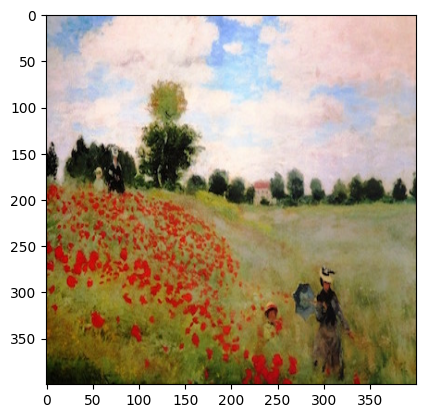

In [131]:
style_image = np.array(Image.open("../images/monet.jpg").resize((img_size, img_size)))
style_image = tf.constant(np.reshape(style_image, ((1,) + style_image.shape)))

print(style_image.shape)
imshow(style_image[0])
plt.show()

<a name='5-3'></a>
### 5.3 Randomly Initialize the Image to be
Now, we will initialize the "generated" image as a noisy image created from the content_image.

* The generated image is slightly correlated with the content image.
* By initializing the pixels of the generated image to be mostly noise but slightly correlated with the content image, this will help the content of the "generated" image more rapidly match the content of the "content" image.

(1, 400, 400, 3)


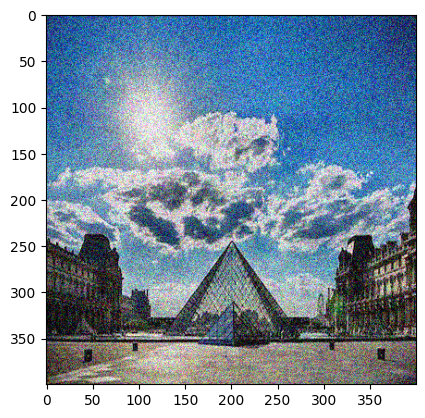

In [132]:
generated_image = tf.Variable(tf.image.convert_image_dtype(content_image, tf.float32))
noise           = tf.random.uniform(tf.shape(generated_image), -0.25, 0.25)
generated_image = tf.add(generated_image, noise)
generated_image = tf.clip_by_value(generated_image, clip_value_min=0.0, clip_value_max=1.0)

print(generated_image.shape)
imshow(generated_image.numpy()[0])
plt.show()

<a name='5-4'></a>
### 5.4 - Load Pre-trained VGG19 Model

In [133]:
def get_layer_outputs(vgg, layer_names):
    """ Creates a vgg model that returns a list of intermediate output values."""

    outputs = [vgg.get_layer(layer[0]).output for layer in layer_names]
    model   = tf.keras.Model([vgg.input], outputs)

    return model

In [134]:
content_layer     = [('block5_conv4', 1)]
vgg_model_outputs = get_layer_outputs(vgg, STYLE_LAYERS + content_layer)

In [135]:
content_target = vgg_model_outputs(content_image)  # Content encoder
style_targets  = vgg_model_outputs(style_image)    # Style encoder

<a name='5-5'></a>
### 5.5 - Compute Total Cost

<a name='5-5-1'></a>
#### 5.5.1 - Compute the Content image Encoding (a_C)

In [136]:
# Assign the content image to be the input of the VGG model.
# Set a_C to be the hidden layer activation from the layer we have selected
preprocessed_content = tf.Variable(tf.image.convert_image_dtype(content_image, tf.float32))
a_C                  = vgg_model_outputs(preprocessed_content)

<a name='5-5-2'></a>
#### 5.5.2 - Compute the Style image Encoding (a_S)

In [137]:
# Assign the input of the model to be the "style" image
preprocessed_style = tf.Variable(tf.image.convert_image_dtype(style_image, tf.float32))
a_S                = vgg_model_outputs(preprocessed_style)

<a name='ex-6'></a>
#### Train Step

In [138]:
optimizer = tf.keras.optimizers.Adam(learning_rate=0.01)

@tf.function()
def train_step(generated_image):
    with tf.GradientTape() as tape:
        # Compute a_G as the vgg_model_outputs for the current generated image
        a_G = vgg_model_outputs(generated_image)
        # Compute the style cost
        J_style = compute_style_cost(a_S, a_G)
        # Compute the content cost
        J_content = compute_content_cost(a_C, a_G)
        # Compute the total cost
        J = total_cost(J_content, J_style, alpha = 10, beta = 40)

    grad = tape.gradient(J, generated_image)

    optimizer.apply_gradients([(grad, generated_image)])
    generated_image.assign(clip_0_1(generated_image))
    return J

In [139]:
generated_image = tf.Variable(generated_image)

<a name='5-6'></a>
### 5.6 - Train the Model

Epoch 0 


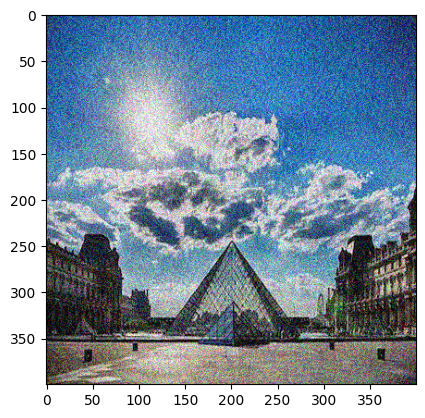

Epoch 250 


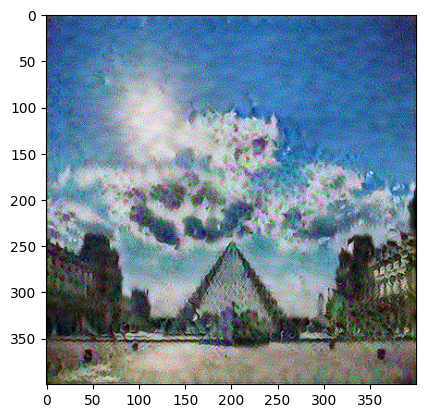

Epoch 500 


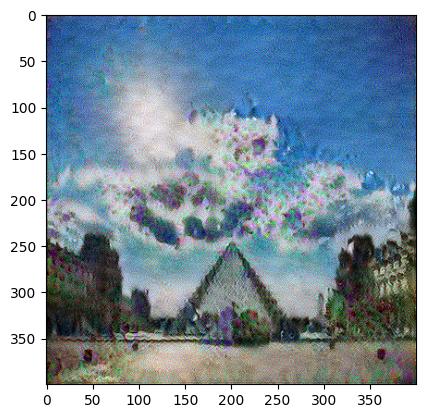

Epoch 750 


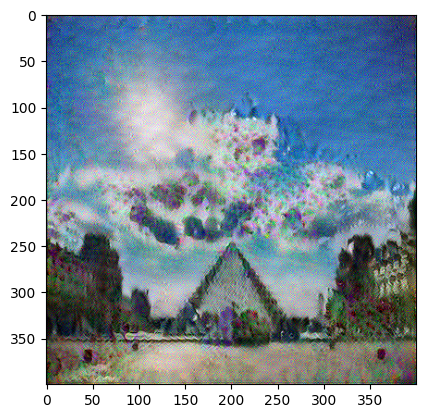

Epoch 1000 


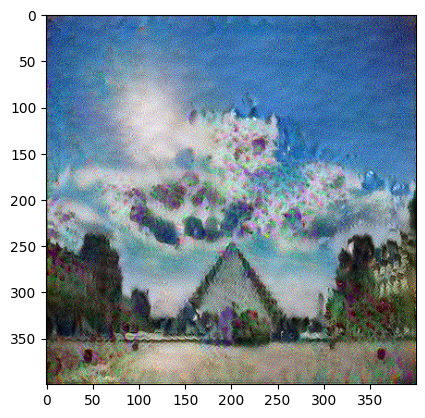

Epoch 1250 


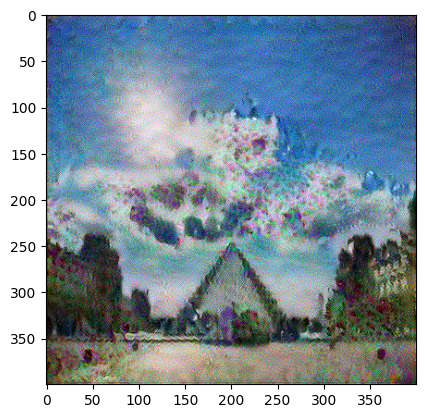

Epoch 1500 


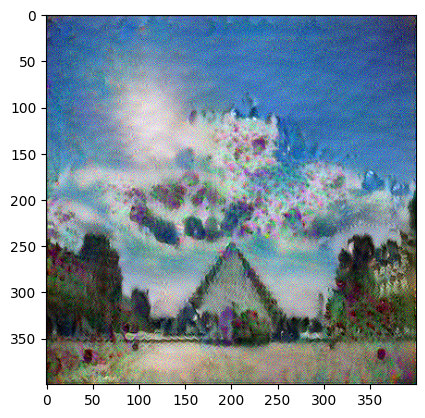

Epoch 1750 


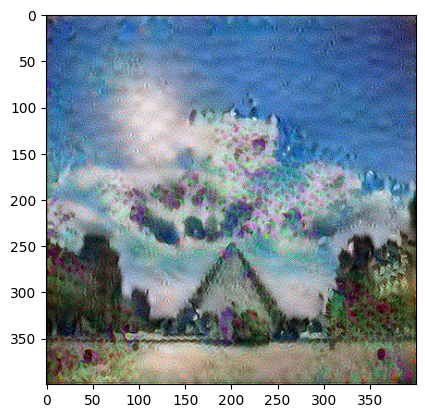

Epoch 2000 


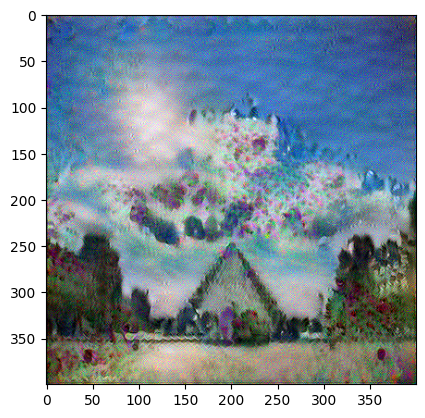

Epoch 2250 


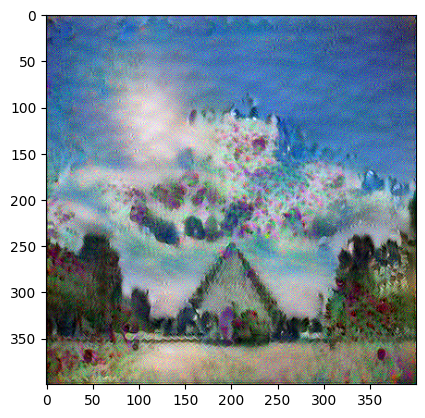

Epoch 2500 


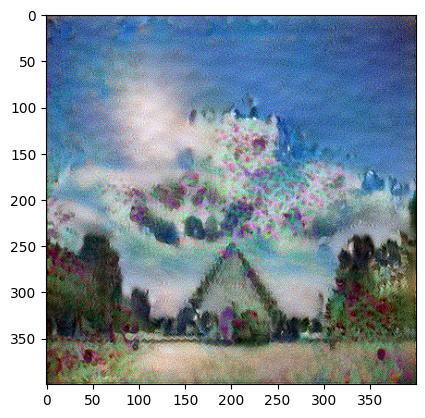

In [140]:
epochs = 2501

for i in range(epochs):
    train_step(generated_image)

    if i % 250 == 0:
        print(f"Epoch {i} ")

    if i % 250 == 0:
        image = tensor_to_image(generated_image)
        imshow(image)
        image.save(f"../images/outputs/image_{i}.jpg")
        plt.show()

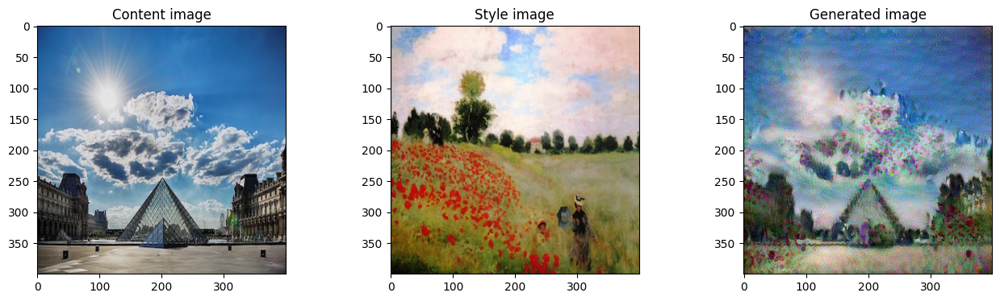

In [141]:
fig = plt.figure(figsize=(16, 4))
ax  = fig.add_subplot(1, 3, 1)
imshow(content_image[0])

ax.title.set_text('Content image')
ax  = fig.add_subplot(1, 3, 2)
imshow(style_image[0])

ax.title.set_text('Style image')
ax  = fig.add_subplot(1, 3, 3)
imshow(generated_image[0])

ax.title.set_text('Generated image')
plt.show()

In [145]:
vgg_model_outputs.save('../models/fine_tuned/vgg_nst_model.keras')
vgg_model_outputs.save_weights('../models/fine_tuned/vgg_nst_weights.weights.h5')
vgg_model_outputs.save('../models/fine_tuned/vgg_nst_model.h5')